In [41]:

import numpy as np
import matplotlib.pyplot as plt
import time

from pathlib import Path
import sys
project_root = Path.cwd().resolve()
if not (project_root / "linsolver.py").is_file():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from linsolver import Equation, solveGaussWithPivoting, solveCG, solveBiCGSTAB, solveMinimalResidual, solveGradientDescent

Lx, Ly = 6.0, 4.0

# Количество узлов, включая граничные
nx, ny = 60, 40

hx = Lx / (nx - 1)
hy = Ly / (ny - 1)

T_left = 20.0
T_right = 30.0
T_bottom = 40.0
T_top = 10.0

# Количество внутренних узлов
mx = nx - 2
my = ny - 2
N = mx * my

def createEquation():
    matrix = np.zeros((N, N))
    b = np.zeros(N)

    # Номер неизвестного внутреннего узла
    def index(i, j):
        return (i - 1) * mx + (j - 1)

    for i in range(1, ny - 1):
        for j in range(1, nx - 1):
            k = index(i, j)

            matrix[k, k] = 2 / hx**2 + 2 / hy**2

            # Левый сосед
            if j > 1:
                matrix[k, index(i, j - 1)] = -1 / hx**2
            else:
                b[k] += T_left / hx**2

            # Правый сосед
            if j < nx - 2:
                matrix[k, index(i, j + 1)] = -1 / hx**2
            else:
                b[k] += T_right / hx**2

            # Нижний сосед
            if i > 1:
                matrix[k, index(i - 1, j)] = -1 / hy**2
            else:
                b[k] += T_bottom / hy**2

            # Верхний сосед
            if i < ny - 2:
                matrix[k, index(i + 1, j)] = -1 / hy**2
            else:
                b[k] += T_top / hy**2
    return Equation(matrix, b)

def visualizeSolution(solution, label):
    T = np.zeros((ny, nx))
    T[:, 0] = T_left
    T[:, -1] = T_right
    T[0, :] = T_bottom
    T[-1, :] = T_top

    T[0, 0] = (T_left + T_bottom) / 2
    T[0, -1] = (T_right + T_bottom) / 2
    T[-1, 0] = (T_left + T_top) / 2
    T[-1, -1] = (T_right + T_top) / 2

    T[1:-1, 1:-1] = np.asarray(solution).reshape(my, mx)
    plt.figure(figsize=(9, 6))
    plt.imshow(T, origin="lower", extent=[0, Lx, 0, Ly], cmap="coolwarm", aspect="equal")
    plt.colorbar(label="Температура, °C")
    plt.xlabel("x, м")
    plt.ylabel("y, м")
    plt.title(label)
    plt.show()

In [42]:
def benchmark(solver, n, label):
    a = createEquation()
    start = time.perf_counter()
    for _ in range(n):
        solution = solver(a)
    duration = (time.perf_counter() - start) / n
    visualizeSolution(solution, label)
    print(f"Duration: {duration}")


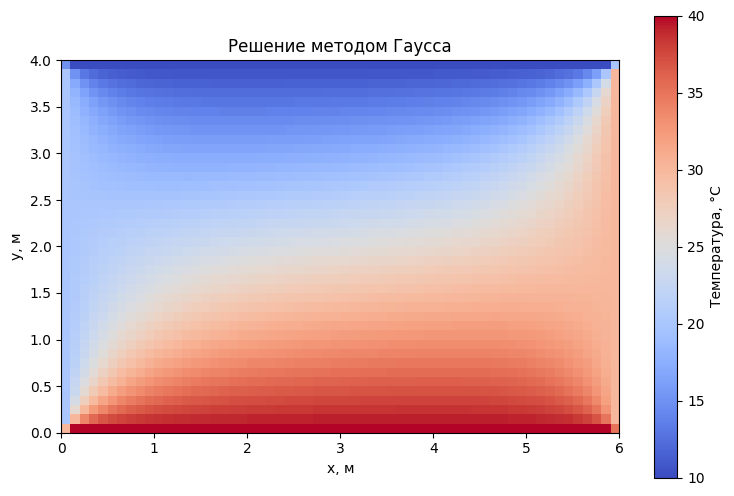

Duration: 4.2728110840544105


In [43]:
benchmark(solveGaussWithPivoting, 1, "Решение методом Гаусса")

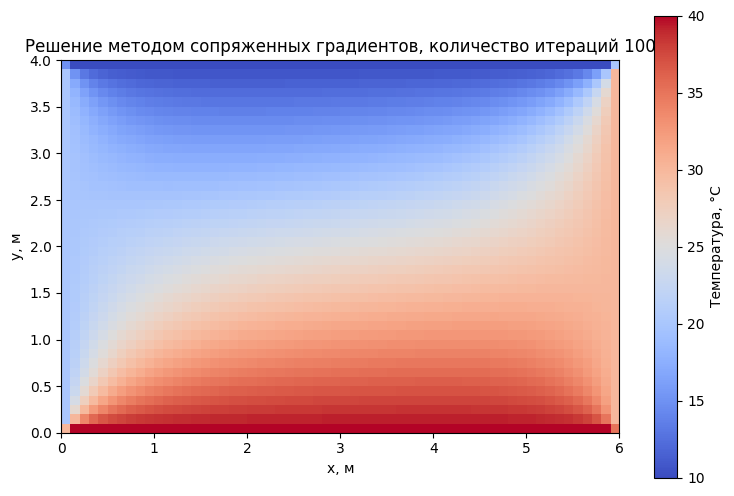

Duration: 0.14525030408985912


In [44]:
n_iter = 100
solver = lambda a: solveCG(a, n_iter)
benchmark(solver, 10, f"Решение методом сопряженных градиентов, количество итераций {n_iter}")

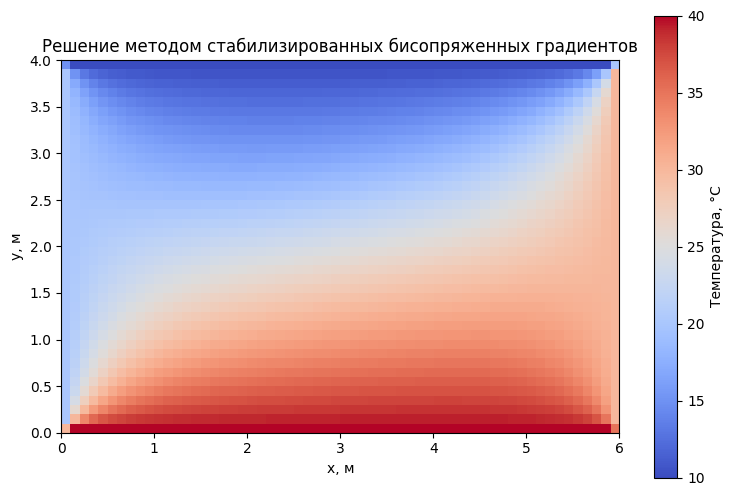

Duration: 0.0746586374938488


In [45]:
n_iter = 50
solver = lambda a: solveBiCGSTAB(a, n_iter)
benchmark(solver, 10, f"Решение методом стабилизированных бисопряженных градиентов")

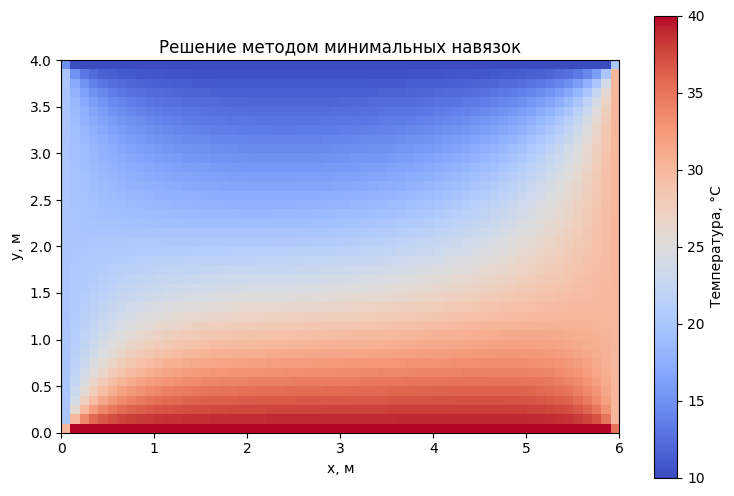

Duration: 1.4498113056955237


In [46]:
n_iter = 1000
solver = lambda a: solveMinimalResidual(a, n_iter)
benchmark(solver, 3, f"Решение методом минимальных навязок")

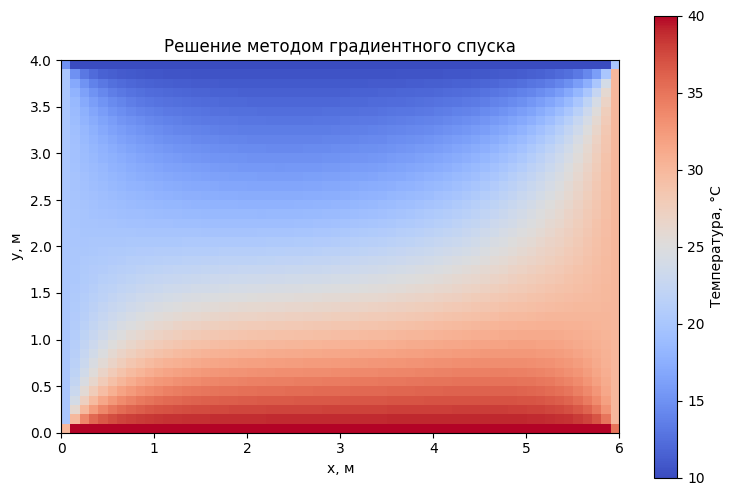

Duration: 1.4134807499746482


In [50]:
n_iter = 1000
solver = lambda a: solveGradientDescent(a, n_iter)
benchmark(solver, 3, f"Решение методом градиентного спуска")

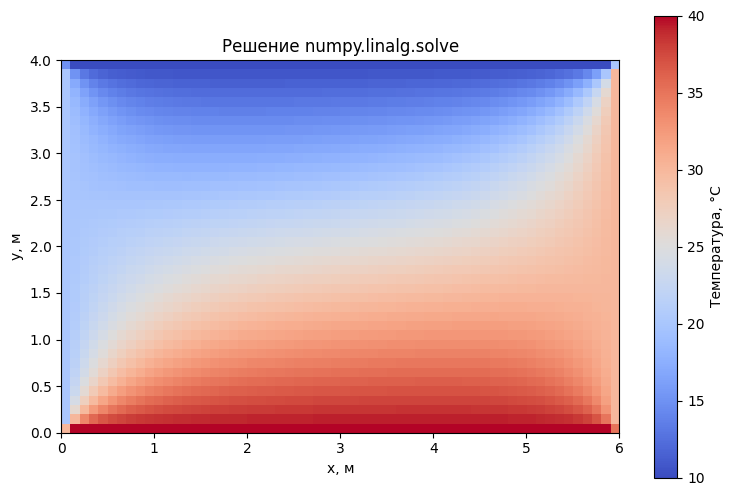

Duration: 0.06556813749484718


In [51]:
solver = lambda a: np.linalg.solve(a.A, a.b)
benchmark(solver, 10, f"Решение numpy.linalg.solve")